## Network Analysis

- https://velog.io/@beoms96/Networkx-Book-1#12-%EB%84%A4%ED%8A%B8%EC%9B%8C%ED%81%AC-%EA%B3%BC%ED%95%99%EC%9D%98-%EB%B2%94%EC%9C%84

- https://brain-nim.tistory.com/35

In [1]:
# Import libraries
import matplotlib.pyplot as plt
from matplotlib.pyplot import imread

import numpy as np
import pandas as pd


from urllib.request import urlopen
import json
import math

from IPython.display import Image
from IPython.display import IFrame

import plotly.io as pio
import plotly.express as px       # 편리한 plot 설정 
import plotly.graph_objects as go # 디테일하게 plot을 설정
import plotly.figure_factory as ff
from plotly.subplots import make_subplots

import geopandas as gpd

import mapclassify as mc 

import ipywidgets

from IPython.display import IFrame

import networkx as nx

In [2]:
# 한글폰트 설정
plt.rc("font", family="Malgun Gothic")

%config InlineBackend.figure_format = 'retina'

pd.options.display.float_format = '{:20.3f}'.format

# pd.set_option('display.max_rows', 50)

# pd.set_option('display.max_rows', None)
# pd.options.display.max_rows = 60

### 수도권 행정동경계 불러오기

In [3]:
bnd_dong_00_2022_2022_2Q_sudo = gpd.read_file(
    "data/bnd_dong_00_2022_2022_2Q_sudo.geojson"
)

bnd_dong_00_2022_2022_2Q_sudo

,BASE_DATE,ADM_CD,ADM_NM,sgis_cd,sqkm,ha,lon,lat,sido_nm,emd_nm,sgg_nm,admdong_cd,geometry
0,20220630,11010530,사직동,11010530,1.158,115.767,126.970,37.574,서울특별시,사직동,종로구,11110530,"POLYGON ((126.97399 37.57823, 126.974 37.57809..."
1,20220630,11010540,삼청동,11010540,1.476,147.609,126.981,37.588,서울특별시,삼청동,종로구,11110540,"POLYGON ((126.97929 37.58349, 126.97931 37.583..."
2,20220630,11010550,부암동,11010550,2.273,227.304,126.964,37.597,서울특별시,부암동,종로구,11110550,"POLYGON ((126.96173 37.60714, 126.96182 37.607..."
3,20220630,11010560,평창동,11010560,8.941,894.066,126.968,37.616,서울특별시,평창동,종로구,11110560,"POLYGON ((126.97508 37.63118, 126.97488 37.630..."
4,20220630,11010570,무악동,11010570,0.369,36.925,126.959,37.577,서울특별시,무악동,종로구,11110570,"POLYGON ((126.95975 37.58001, 126.96006 37.579..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1137,20220630,31101513,삼송2동,31101513,2.520,252.029,126.875,37.652,경기도,삼송2동,고양시 덕양구,41281577,"POLYGON ((126.87801 37.66032, 126.87848 37.660..."
1138,20220630,31101514,행신3동,31101514,0.582,58.177,126.840,37.625,경기도,행신3동,고양시 덕양구,41281655,"POLYGON ((126.84123 37.62933, 126.84126 37.629..."
1139,20220630,31103511,중산1동,31103511,1.387,138.732,126.783,37.691,경기도,중산1동,고양시 일산동구,41285525,"POLYGON ((126.78978 37.6884, 126.78953 37.6877..."
1140,20220630,31104511,탄현1동,31104511,0.912,91.213,126.766,37.694,경기도,탄현1동,고양시 일산서구,41287545,"POLYGON ((126.77606 37.69384, 126.77602 37.693..."


In [4]:
bnd_dong_00_2022_2022_2Q_sudo.count()

BASE_DATE     1142
ADM_CD        1142
ADM_NM        1142
sgis_cd       1142
sqkm          1142
ha            1142
lon           1142
lat           1142
sido_nm       1142
emd_nm        1142
sgg_nm        1142
admdong_cd    1142
geometry      1142
dtype: int64

### 성남시 경계 추출

In [5]:
bnd_dong_00_2022_2022_2Q_sudo.sgg_nm.unique()

<StringArray>
[     '종로구',       '중구',      '용산구',      '성동구',      '광진구',     '동대문구',
      '중랑구',      '성북구',      '강북구',      '도봉구',      '노원구',      '은평구',
     '서대문구',      '마포구',      '양천구',      '강서구',      '구로구',      '금천구',
     '영등포구',      '동작구',      '관악구',      '서초구',      '강남구',      '송파구',
      '강동구',       '동구',      '연수구',      '남동구',      '부평구',      '계양구',
       '서구',     '미추홀구',      '강화군',      '옹진군',  '수원시 장안구',  '수원시 권선구',
  '수원시 팔달구',  '수원시 영통구',  '성남시 수정구',  '성남시 중원구',  '성남시 분당구',     '의정부시',
  '안양시 만안구',  '안양시 동안구',      '부천시',      '광명시',      '평택시',     '동두천시',
  '안산시 상록구',  '안산시 단원구',  '고양시 덕양구', '고양시 일산동구', '고양시 일산서구',      '과천시',
      '구리시',     '남양주시',      '오산시',      '시흥시',      '군포시',      '의왕시',
      '하남시',  '용인시 처인구',  '용인시 기흥구',  '용인시 수지구',      '파주시',      '이천시',
      '안성시',      '김포시',      '화성시',      '광주시',      '양주시',      '포천시',
      '여주시',      '연천군',      '가평군',      '양평군']
Length: 76, dtype: str

In [6]:
bnd_dong_00_2022_2022_2Q_sungnam=bnd_dong_00_2022_2022_2Q_sudo.query("sgg_nm.isin(['성남시 수정구','성남시 중원구','성남시 분당구'])")
bnd_dong_00_2022_2022_2Q_sungnam.head()

,BASE_DATE,ADM_CD,ADM_NM,sgis_cd,sqkm,ha,lon,lat,sido_nm,emd_nm,sgg_nm,admdong_cd,geometry
625,20220630,31021510,신흥1동,31021510,0.323,32.260,127.141,37.441,경기도,신흥1동,성남시 수정구,41131510,"POLYGON ((127.14093 37.43766, 127.14092 37.437..."
626,20220630,31021520,신흥2동,31021520,1.140,114.028,127.148,37.450,경기도,신흥2동,성남시 수정구,41131520,"POLYGON ((127.15061 37.45703, 127.15051 37.456..."
627,20220630,31021530,신흥3동,31021530,0.321,32.116,127.147,37.443,경기도,신흥3동,성남시 수정구,41131530,"POLYGON ((127.145 37.43972, 127.14485 37.43964..."
628,20220630,31021540,태평1동,31021540,1.341,134.108,127.124,37.446,경기도,태평1동,성남시 수정구,41131540,"POLYGON ((127.12269 37.45485, 127.1226 37.4544..."
629,20220630,31021550,태평2동,31021550,0.482,48.225,127.136,37.448,경기도,태평2동,성남시 수정구,41131550,"POLYGON ((127.13749 37.45242, 127.13744 37.452..."


### 전처리된 성남 거주지-생활지 생활인구 데이터 불러오기

- 2022년 06월 13일 월요일 ~ 2022년 06월 17일 금요일 5일간 데이터를 행정동별, 시간대별로 평균.
- 거주지 행정동(rsdn_adm)의 센트로이드 위경도 좌표(rsdn_lon, rsdn_lat) - 오후 2시 활동지 행정동(adm)의 센트로이드 위경도 좌표(lon, lat)로 네트워크 시각화와 분석

In [7]:
sungnam_mid_2pm=pd.read_csv('data/sungnam_mid_2pm.csv')
sungnam_mid_2pm

,sgis_cd,sido_nm,admdong_cd,sgg_nm,emd_nm,lon,lat,rsdn_sgis_cd,rsdn_sido_nm,rsdn_admdong_cd,rsdn_sgg_nm,rsdn_emd_nm,rsdn_lon,rsdn_lat,tot,adm,rsdn_adm
0,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,3522.527,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 신흥1동
1,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021520,경기도,41131520,성남시 수정구,신흥2동,127.148,37.450,125.335,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 신흥2동
2,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021530,경기도,41131530,성남시 수정구,신흥3동,127.147,37.443,567.457,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 신흥3동
3,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021540,경기도,41131540,성남시 수정구,태평1동,127.124,37.446,119.491,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 태평1동
4,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021550,경기도,41131550,성남시 수정구,태평2동,127.136,37.448,356.621,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 태평2동
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2450,31023780,경기도,41135545,성남시 분당구,정자동,127.112,37.367,31023740,경기도,41135655,성남시 분당구,삼평동,127.108,37.402,261.004,경기도 성남시 분당구 정자동,경기도 성남시 분당구 삼평동
2451,31023780,경기도,41135545,성남시 분당구,정자동,127.112,37.367,31023750,경기도,41135650,성남시 분당구,판교동,127.093,37.388,164.463,경기도 성남시 분당구 정자동,경기도 성남시 분당구 판교동
2452,31023780,경기도,41135545,성남시 분당구,정자동,127.112,37.367,31023760,경기도,41135657,성남시 분당구,백현동,127.110,37.390,250.063,경기도 성남시 분당구 정자동,경기도 성남시 분당구 백현동
2453,31023780,경기도,41135545,성남시 분당구,정자동,127.112,37.367,31023770,경기도,41135550,성남시 분당구,정자1동,127.107,37.371,2543.501,경기도 성남시 분당구 정자동,경기도 성남시 분당구 정자1동


In [8]:
sungnam_mid_2pm.columns

Index(['sgis_cd', 'sido_nm', 'admdong_cd', 'sgg_nm', 'emd_nm', 'lon', 'lat',
       'rsdn_sgis_cd', 'rsdn_sido_nm', 'rsdn_admdong_cd', 'rsdn_sgg_nm',
       'rsdn_emd_nm', 'rsdn_lon', 'rsdn_lat', 'tot', 'adm', 'rsdn_adm'],
      dtype='str')

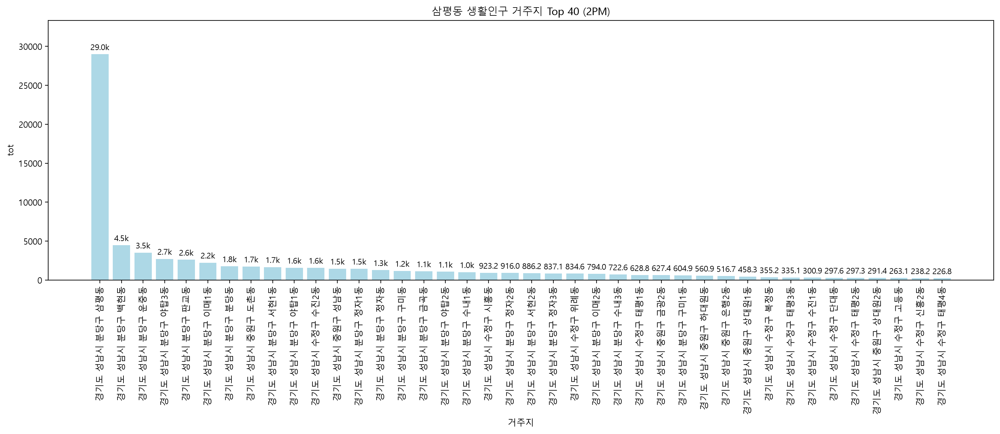

In [9]:
import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter
from pathlib import Path

# 삼평동의 tot 상위 40개
df = (
    sungnam_mid_2pm.query('emd_nm == "삼평동"')
    .sort_values(by="tot", ascending=False)
    .head(40)
)

fig, ax = plt.subplots(figsize=(16, 7), facecolor="white")
ax.set_facecolor("white")

bars = ax.bar(df["rsdn_adm"].astype(str), df["tot"], color="lightblue")

# 막대 위에 값 표시: 1,000 → 1k 등
formatter = EngFormatter(places=1, sep="")
ax.bar_label(
    bars,
    labels=[formatter(value) for value in df["tot"]],
    padding=3,
    fontsize=9,
)

ax.set_xlabel("거주지")
ax.set_ylabel("tot")
ax.set_title("삼평동 생활인구 거주지 Top 40 (2PM)")
ax.tick_params(axis="x", labelrotation=90)
ax.margins(y=0.15)

plt.tight_layout()

plt.show()

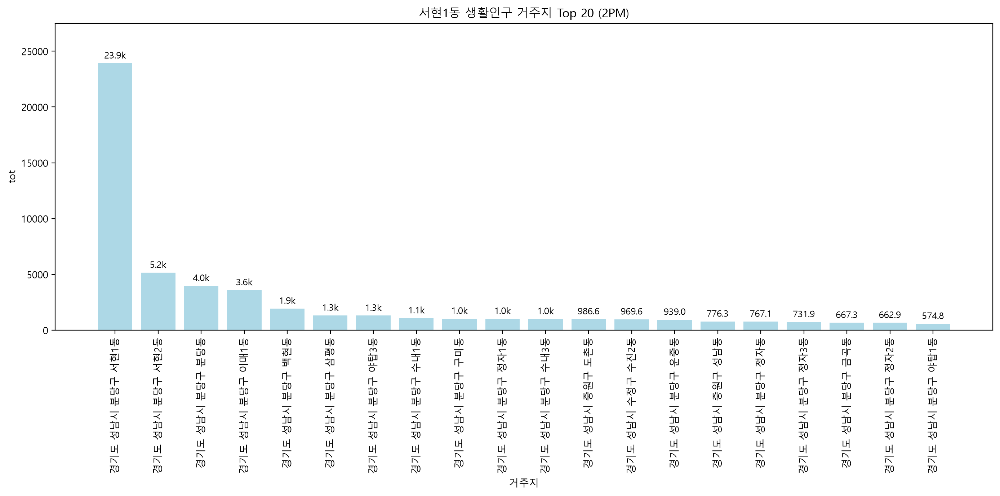

In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter
from pathlib import Path

df = (
    sungnam_mid_2pm.query('emd_nm == "서현1동"')
    .sort_values(by="tot", ascending=False)
    .head(20)
)

fig, ax = plt.subplots(figsize=(14, 7), facecolor="white")
ax.set_facecolor("white")

bars = ax.bar(df["rsdn_adm"].astype(str), df["tot"], color="lightblue")

formatter = EngFormatter(places=1, sep="")
ax.bar_label(
    bars,
    labels=[formatter(value) for value in df["tot"]],
    padding=3,
    fontsize=9,
)

ax.set_xlabel("거주지")
ax.set_ylabel("tot")
ax.set_title("서현1동 생활인구 거주지 Top 20 (2PM)")
ax.tick_params(axis="x", labelrotation=90)
ax.margins(y=0.15)

plt.tight_layout()

plt.show()

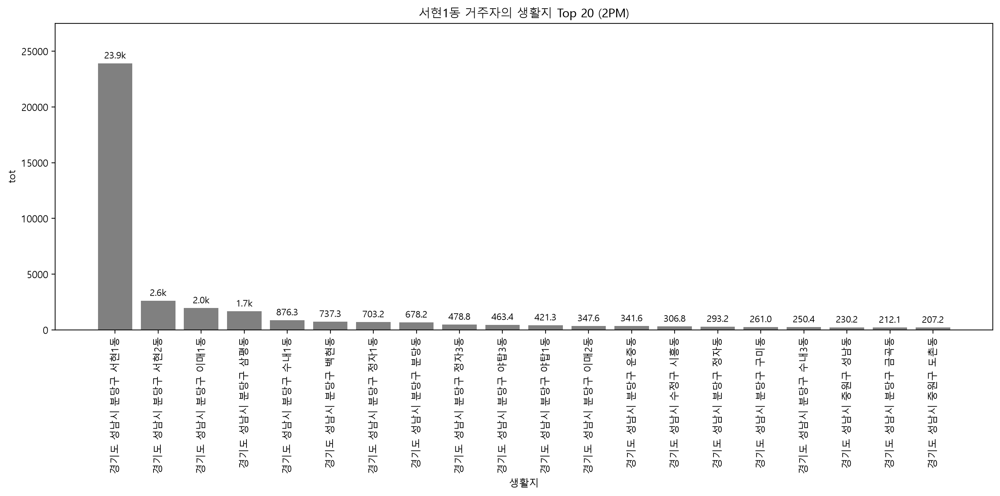

In [11]:
import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter
from pathlib import Path

df = (
    sungnam_mid_2pm.query('rsdn_emd_nm == "서현1동"')
    .sort_values(by="tot", ascending=False)
    .head(20)
)

fig, ax = plt.subplots(figsize=(14, 7), facecolor="white")
ax.set_facecolor("white")

bars = ax.bar(df["adm"].astype(str), df["tot"], color="grey")

formatter = EngFormatter(places=1, sep="")
ax.bar_label(
    bars,
    labels=[formatter(value) for value in df["tot"]],
    padding=3,
    fontsize=9,
)

ax.set_xlabel("생활지")
ax.set_ylabel("tot")
ax.set_title("서현1동 거주자의 생활지 Top 20 (2PM)")
ax.tick_params(axis="x", labelrotation=90)
ax.margins(y=0.15)

plt.tight_layout()

Path("html").mkdir(parents=True, exist_ok=True)
fig.savefig(
    "html/거주지_서현1동_생활지Top 20_2PM.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [12]:
# 루프제거
sungnam_mid_2pm_no_loop=sungnam_mid_2pm[sungnam_mid_2pm['admdong_cd'] != sungnam_mid_2pm['rsdn_admdong_cd']]
sungnam_mid_2pm_no_loop

,sgis_cd,sido_nm,admdong_cd,sgg_nm,emd_nm,lon,lat,rsdn_sgis_cd,rsdn_sido_nm,rsdn_admdong_cd,rsdn_sgg_nm,rsdn_emd_nm,rsdn_lon,rsdn_lat,tot,adm,rsdn_adm
1,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021520,경기도,41131520,성남시 수정구,신흥2동,127.148,37.450,125.335,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 신흥2동
2,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021530,경기도,41131530,성남시 수정구,신흥3동,127.147,37.443,567.457,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 신흥3동
3,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021540,경기도,41131540,성남시 수정구,태평1동,127.124,37.446,119.491,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 태평1동
4,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021550,경기도,41131550,성남시 수정구,태평2동,127.136,37.448,356.621,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 태평2동
5,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021560,경기도,41131560,성남시 수정구,태평3동,127.132,37.445,114.033,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 태평3동
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2449,31023780,경기도,41135545,성남시 분당구,정자동,127.112,37.367,31023720,경기도,41135665,성남시 분당구,구미1동,127.093,37.352,830.258,경기도 성남시 분당구 정자동,경기도 성남시 분당구 구미1동
2450,31023780,경기도,41135545,성남시 분당구,정자동,127.112,37.367,31023740,경기도,41135655,성남시 분당구,삼평동,127.108,37.402,261.004,경기도 성남시 분당구 정자동,경기도 성남시 분당구 삼평동
2451,31023780,경기도,41135545,성남시 분당구,정자동,127.112,37.367,31023750,경기도,41135650,성남시 분당구,판교동,127.093,37.388,164.463,경기도 성남시 분당구 정자동,경기도 성남시 분당구 판교동
2452,31023780,경기도,41135545,성남시 분당구,정자동,127.112,37.367,31023760,경기도,41135657,성남시 분당구,백현동,127.110,37.390,250.063,경기도 성남시 분당구 정자동,경기도 성남시 분당구 백현동


### 성남시 생활이동 네트워크 시각화

In [13]:
df=sungnam_mid_2pm_no_loop[['adm','lon','lat','rsdn_adm','rsdn_lon','rsdn_lat','tot']]
df.query("tot>100") # 상위 100개만 추출 - 전체를 다하면 너무 많아서 시각화가 어려움

,adm,lon,lat,rsdn_adm,rsdn_lon,rsdn_lat,tot
1,경기도 성남시 수정구 신흥1동,127.141,37.441,경기도 성남시 수정구 신흥2동,127.148,37.450,125.335
2,경기도 성남시 수정구 신흥1동,127.141,37.441,경기도 성남시 수정구 신흥3동,127.147,37.443,567.457
3,경기도 성남시 수정구 신흥1동,127.141,37.441,경기도 성남시 수정구 태평1동,127.124,37.446,119.491
4,경기도 성남시 수정구 신흥1동,127.141,37.441,경기도 성남시 수정구 태평2동,127.136,37.448,356.621
5,경기도 성남시 수정구 신흥1동,127.141,37.441,경기도 성남시 수정구 태평3동,127.132,37.445,114.033
...,...,...,...,...,...,...,...
2449,경기도 성남시 분당구 정자동,127.112,37.367,경기도 성남시 분당구 구미1동,127.093,37.352,830.258
2450,경기도 성남시 분당구 정자동,127.112,37.367,경기도 성남시 분당구 삼평동,127.108,37.402,261.004
2451,경기도 성남시 분당구 정자동,127.112,37.367,경기도 성남시 분당구 판교동,127.093,37.388,164.463
2452,경기도 성남시 분당구 정자동,127.112,37.367,경기도 성남시 분당구 백현동,127.110,37.390,250.063


In [14]:
# GeoDataFrame으로 변환
gdf = gpd.GeoDataFrame(sungnam_mid_2pm_no_loop, 
                                       geometry=gpd.points_from_xy(sungnam_mid_2pm_no_loop['lon'], sungnam_mid_2pm_no_loop['lat']),
                                       crs='epsg:4326')

gdf['geometry_rsdn'] = gpd.points_from_xy(sungnam_mid_2pm_no_loop['rsdn_lon'], sungnam_mid_2pm_no_loop['rsdn_lat'])

gdf.head()

,sgis_cd,sido_nm,admdong_cd,sgg_nm,emd_nm,lon,lat,rsdn_sgis_cd,rsdn_sido_nm,rsdn_admdong_cd,rsdn_sgg_nm,rsdn_emd_nm,rsdn_lon,rsdn_lat,tot,adm,rsdn_adm,geometry,geometry_rsdn
1,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021520,경기도,41131520,성남시 수정구,신흥2동,127.148,37.450,125.335,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 신흥2동,POINT (127.14055 37.44092),POINT (127.14809 37.44969)
2,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021530,경기도,41131530,성남시 수정구,신흥3동,127.147,37.443,567.457,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 신흥3동,POINT (127.14055 37.44092),POINT (127.14669 37.44293)
3,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021540,경기도,41131540,성남시 수정구,태평1동,127.124,37.446,119.491,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 태평1동,POINT (127.14055 37.44092),POINT (127.12359 37.44576)
4,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021550,경기도,41131550,성남시 수정구,태평2동,127.136,37.448,356.621,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 태평2동,POINT (127.14055 37.44092),POINT (127.13641 37.4476)
5,31021510,경기도,41131510,성남시 수정구,신흥1동,127.141,37.441,31021560,경기도,41131560,성남시 수정구,태평3동,127.132,37.445,114.033,경기도 성남시 수정구 신흥1동,경기도 성남시 수정구 태평3동,POINT (127.14055 37.44092),POINT (127.13218 37.4454)


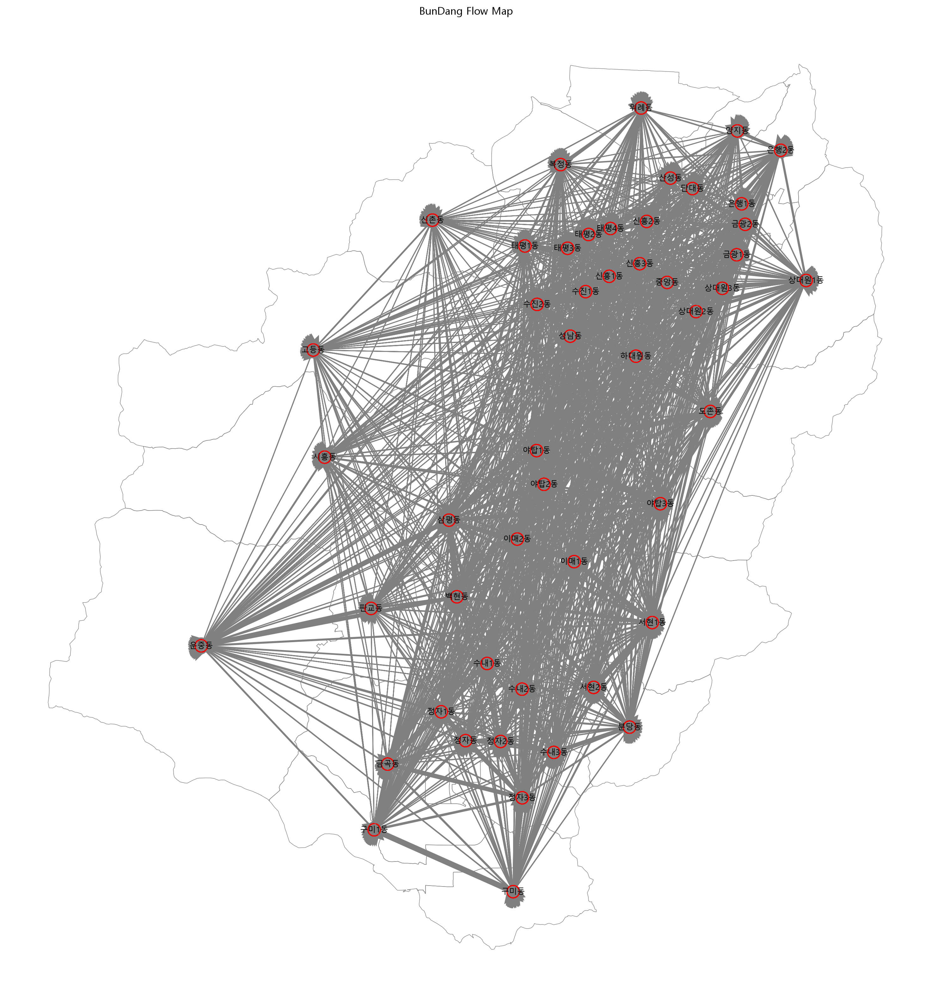

In [15]:
# 기본값으로 시각화
# Create the plot
fig, ax = plt.subplots(figsize=(20, 20))


# Plot flow lines
for index, row in gdf.query("tot>0").iterrows():
    ax.arrow(row['geometry_rsdn'].x, row['geometry_rsdn'].y,
             row['geometry'].x - row['geometry_rsdn'].x,
             row['geometry'].y - row['geometry_rsdn'].y,
             width=0.001 * row['tot'] / max(gdf['tot']),  # Scale arrow width
             head_width=0.0025, head_length=0.0025, fc='grey', ec='grey')


# Plot location points
gdf.plot(ax=ax, marker='o', color='none', markersize=200,  edgecolor="red")



# 행정동 경계
bnd_dong_00_2022_2022_2Q_sungnam.plot(ax = ax, color='none', edgecolor='grey', linewidth=0.5) 

# 중심점에 동 이름 라벨 표시 
for idx, row in bnd_dong_00_2022_2022_2Q_sungnam.iterrows():
    centroid = row.geometry.centroid
    ax.text(
        centroid.x, centroid.y,
        row['emd_nm'], 
        fontsize=9,
        color='black',
        ha='center',
        va='center'
    )



ax.set_title('BunDang Flow Map')
ax.set_axis_off()

plt.show()

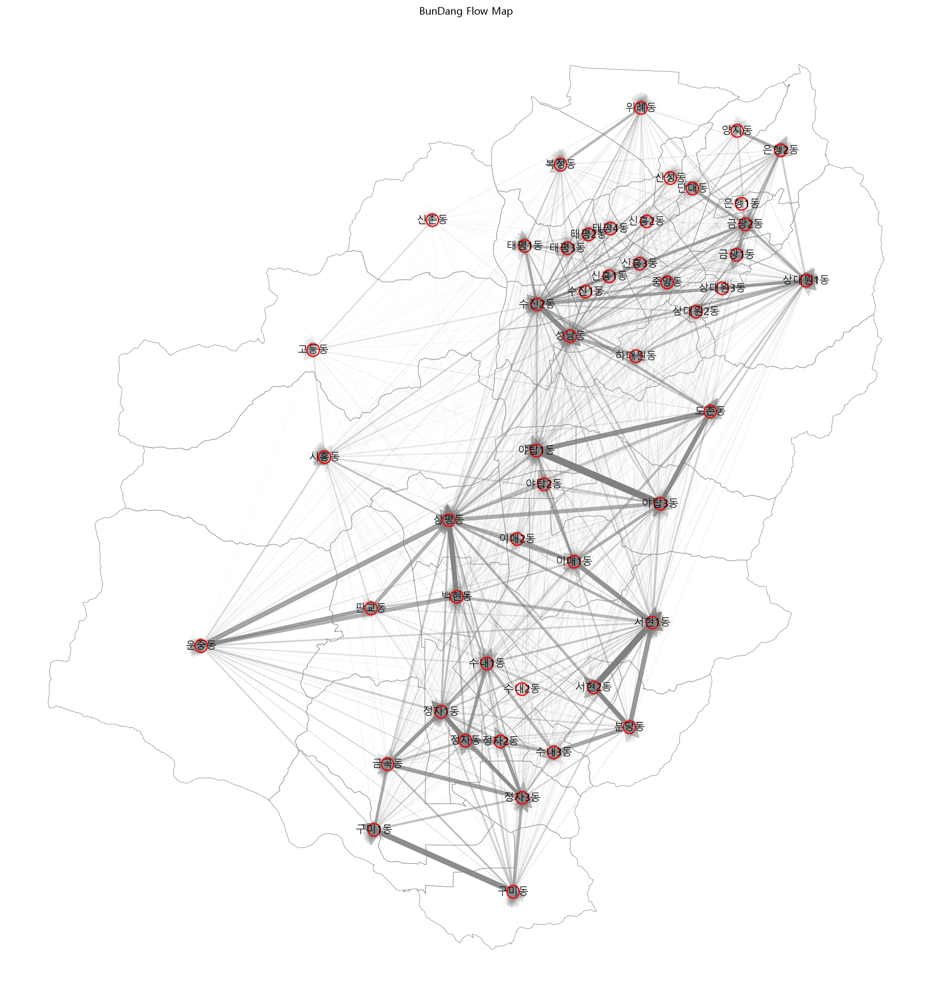

In [16]:
# 링크의 두께를 tot 값에 따라 조정하고, 불투명도를 적용하여 시각화
# tot 값 정규화 (0~1)
gdf['alpha'] = (gdf['tot'] - gdf['tot'].min()) / (gdf['tot'].max() - gdf['tot'].min())

# Create the plot
fig, ax = plt.subplots(figsize=(20, 20))


# Plot flow lines
for index, row in gdf.query("tot > 0").iterrows():
    ax.arrow(
        row['geometry_rsdn'].x, row['geometry_rsdn'].y,
        row['geometry'].x - row['geometry_rsdn'].x,
        row['geometry'].y - row['geometry_rsdn'].y,
        width=0.001 * row['tot'] / gdf['tot'].max(),  # Scale arrow width
        head_width=0.0025,
        head_length=0.0025,
        fc='grey',
        ec='grey',
        alpha=row['alpha']  # 불투명도 적용
    )

# Plot location points
gdf.plot(ax=ax, marker='o', color='none', markersize=200, edgecolor="red")


# 행정동 경계
bnd_dong_00_2022_2022_2Q_sungnam.plot(ax = ax, color='none', edgecolor='grey', linewidth=0.5) 

# 중심점에 동 이름 라벨 표시 
for idx, row in bnd_dong_00_2022_2022_2Q_sungnam.iterrows():
    centroid = row.geometry.centroid
    ax.text(
        centroid.x, centroid.y,
        row['emd_nm'], 
        fontsize=12,
        color='black',
        ha='center',
        va='center'
    )

ax.set_title('BunDang Flow Map')
ax.set_axis_off()

plt.show()

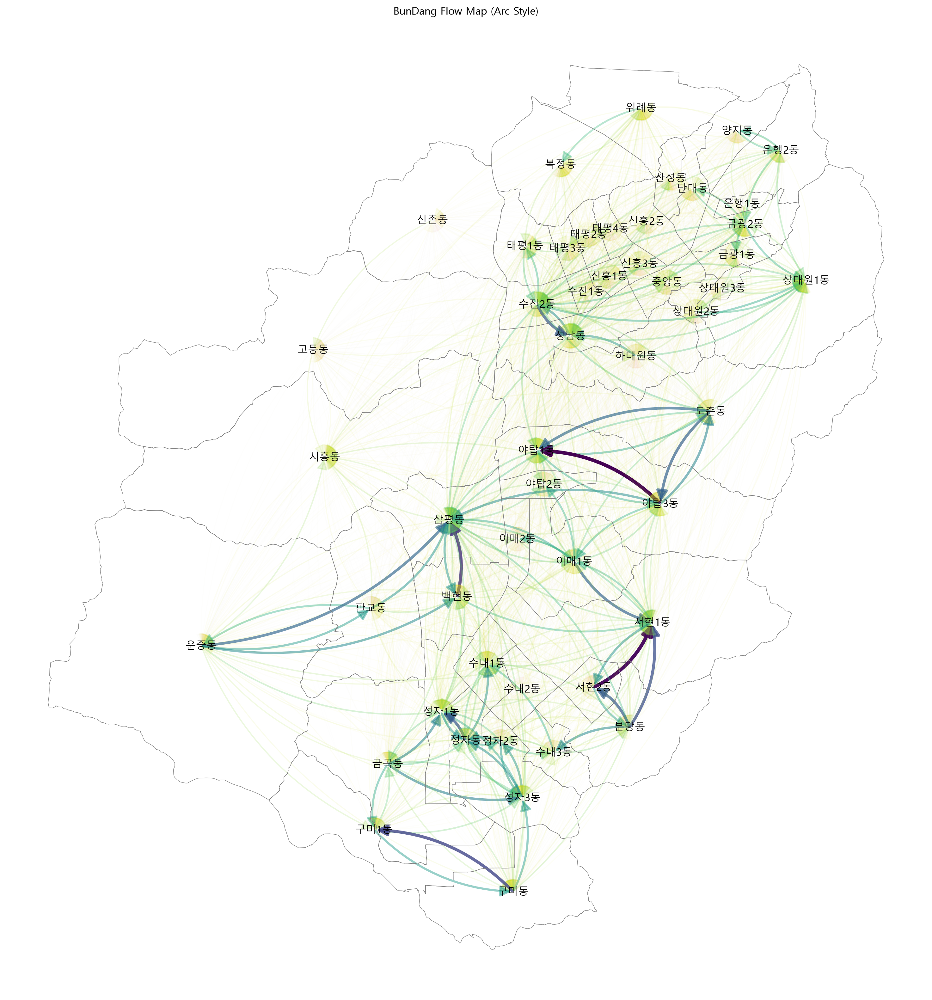

In [17]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.patches import FancyArrowPatch

cmap = mpl.colormaps['viridis']  # 또는 'plasma', 'coolwarm' 등
norm = mcolors.Normalize(vmin=gdf['tot'].min(), vmax=gdf['tot'].max())


# 정규화 (0~1) alpha 값 설정
gdf['alpha'] = (gdf['tot'] - gdf['tot'].min()) / (gdf['tot'].max() - gdf['tot'].min())


# Plot 생성
fig, ax = plt.subplots(figsize=(20, 20))

# 아크 화살표로 흐름선 표현
for index, row in gdf.query("tot > 0").iterrows():
    x_start, y_start = row['geometry_rsdn'].x, row['geometry_rsdn'].y
    x_end, y_end = row['geometry'].x, row['geometry'].y

    color = cmap(1-norm(row['tot']))

    arrow = FancyArrowPatch(
        (x_start, y_start), (x_end, y_end),
        connectionstyle="arc3,rad=0.2",  # 아크 스타일
        arrowstyle='-|>',
        color=color,
        alpha=row['alpha'],
        linewidth=1 + 3 * row['alpha'],
        mutation_scale=25
    )
    ax.add_patch(arrow)

# 위치 포인트 (도착지)
# gdf.plot(ax=ax, marker='o', color='none', markersize=200, edgecolor="red")

# 행정동 경계
bnd_dong_00_2022_2022_2Q_sungnam.plot(ax=ax, color='none', edgecolor='grey', linewidth=0.5)

# 행정동 이름 라벨
for idx, row in bnd_dong_00_2022_2022_2Q_sungnam.iterrows():
    centroid = row.geometry.centroid
    ax.text(
        centroid.x, centroid.y,
        row['emd_nm'],
        fontsize=12,
        color='black',
        ha='center',
        va='center'
    )

# 타이틀 및 축 제거
ax.set_title('BunDang Flow Map (Arc Style)')
ax.set_axis_off()

plt.show()

### 성남 네트워크 분석

In [18]:
import networkx as nx
import matplotlib.pyplot as plt

# 같은 거주지 → 생활지 조합의 이동량 합산
edges = (
    sungnam_mid_2pm_no_loop
    .groupby(
        ["rsdn_admdong_cd", "admdong_cd"],
        as_index=False
    )["tot"]
    .sum()
)

edges

,rsdn_admdong_cd,admdong_cd,tot
0,41131510,41131520,42.365
1,41131510,41131530,378.641
2,41131510,41131540,107.174
3,41131510,41131550,369.130
4,41131510,41131560,164.657
...,...,...,...
2400,41135680,41135655,3521.066
2401,41135680,41135657,2758.624
2402,41135680,41135662,717.754
2403,41135680,41135665,881.673


In [19]:
# NetworkX 그래프 생성
g = nx.from_pandas_edgelist(
    edges,
    source="rsdn_admdong_cd",
    target="admdong_cd",
    edge_attr="tot",
    create_using=nx.DiGraph(),
)

g

In [20]:
# 앞서 사용한 중심성 코드와 가중치 이름 통일
nx.set_edge_attributes(
    g,
    {(u, v): data["tot"] for u, v, data in g.edges(data=True)},
    "weight",
)

In [21]:
next(iter(g.edges(data=True)))
# 예: (출발동, 도착동, {'tot': 123.0, 'weight': 123.0})

(41131510, 41131520, {'tot': 42.364561424035685, 'weight': 42.364561424035685})

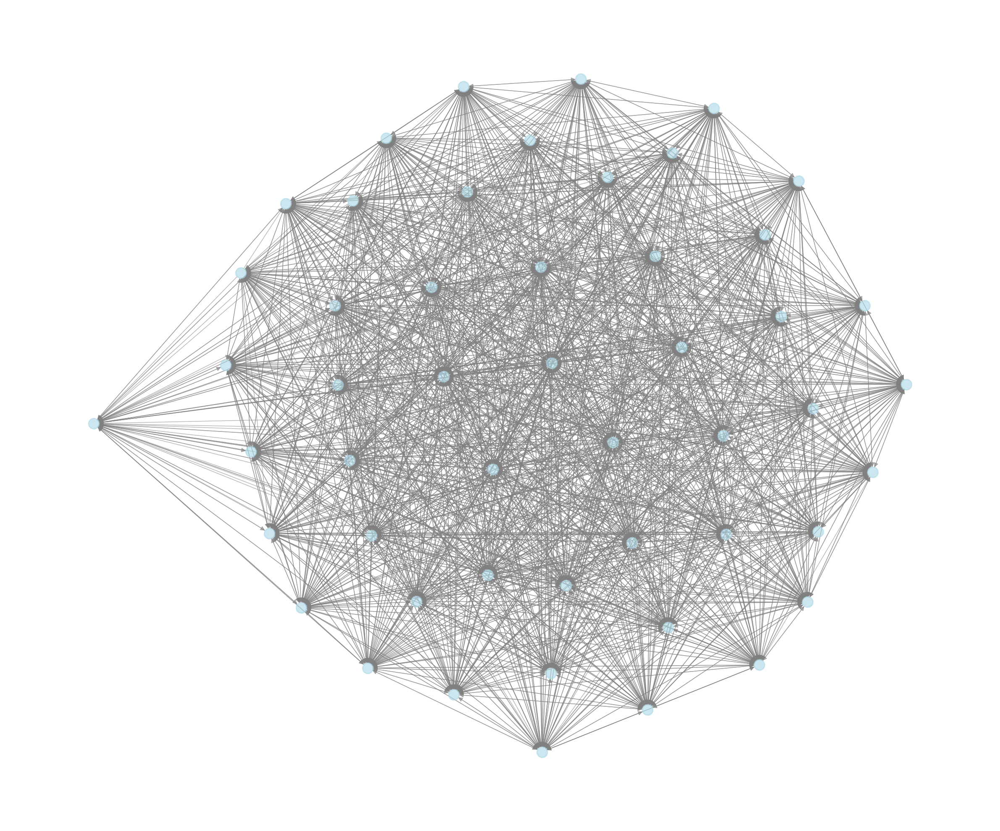

In [22]:
# 그래프 시각화
fig, ax = plt.subplots(figsize=(12, 10))
pos = nx.spring_layout(g, seed=42, weight=None)

nx.draw_networkx(
    g,
    pos=pos,
    ax=ax,
    node_size=80,
    node_color="lightblue",
    edge_color="grey",
    width=0.5,
    alpha=0.6,
    arrows=True,
    arrowsize=8,
    with_labels=False,
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

In [23]:
# 연결중심성: 이동량이 아닌 연결 개수 기준
degCent = nx.degree_centrality(g)
indegCent = nx.in_degree_centrality(g)
outdegCent = nx.out_degree_centrality(g)

# 이동량 합계
inStrength = dict(g.in_degree(weight="weight"))
outStrength = dict(g.out_degree(weight="weight"))

# 근접중심성: 연결 단계 수 기준
closeCent = nx.closeness_centrality(g)  # 유입
closeCent_out = nx.closeness_centrality(g.reverse(copy=False))  # 유출

# 비가중 매개중심성
btwnCent = nx.betweenness_centrality(
    g,
    normalized=True,
    endpoints=False,
    weight=None,
)

# 가중 매개중심성에 사용할 거리 설정
# 앞서 양수 이동량만 남겼으므로 역수 계산 가능
for u, v, data in g.edges(data=True):
    data["distance"] = 1.0 / data["weight"]

# 가중 매개중심성: 이동량이 클수록 짧은 거리로 간주
btwnCent_w = nx.betweenness_centrality(
    g,
    normalized=True,
    endpoints=False,
    weight="distance",
)

# PageRank: 비가중 / 이동량 가중
pageRank = nx.pagerank(
    g, alpha=0.9, weight=None, max_iter=1000
)
pageRank_w = nx.pagerank(
    g, alpha=0.9, weight="weight", max_iter=1000
)


In [24]:
pageRank_w

{41131510: 0.009336157880318276,
 41131520: 0.006439055308843967,
 41131530: 0.010441301936031152,
 41131540: 0.015422228478563275,
 41131550: 0.010792732758747215,
 41131560: 0.01230814746221819,
 41131561: 0.006734305568427671,
 41131570: 0.006740125745338809,
 41131580: 0.03946944671476773,
 41131590: 0.010307178404248529,
 41131600: 0.007715280258348273,
 41131610: 0.006358604234354104,
 41131620: 0.012868462432307425,
 41131625: 0.012344446155932219,
 41131630: 0.005377985225123586,
 41131640: 0.008736969554285727,
 41131650: 0.023282973895674748,
 41133510: 0.03467520804513044,
 41133525: 0.01497640370585981,
 41133530: 0.01219324588539427,
 41133540: 0.019621437606758992,
 41133550: 0.003553897287863949,
 41133560: 0.00977531502157346,
 41133570: 0.030452895608798037,
 41133580: 0.011112321247359674,
 41133590: 0.005977376734752548,
 41133660: 0.009558055345876617,
 41133670: 0.026743998228648265,
 41135510: 0.015115213928999309,
 41135520: 0.032764617021262085,
 41135530: 0.005

In [25]:
import pandas as pd

centrality_df = pd.DataFrame({
    "degree": degCent,
    "in_degree": indegCent,
    "out_degree": outdegCent,
    "in_strength": inStrength,
    "out_strength": outStrength,
    "closeness_in": closeCent,
    "closeness_out": closeCent_out,
    "betweenness": btwnCent,
    "betweenness_w": btwnCent_w,
    "pagerank": pageRank,
    "pagerank_w": pageRank_w,
}).rename_axis("admdong_cd")

centrality_df.sort_values("pagerank_w", ascending=False)

,degree,in_degree,out_degree,in_strength,out_strength,closeness_in,closeness_out,betweenness,betweenness_w,pagerank,pagerank_w
admdong_cd,,,,,,,,,,,
41135655,2.000,1.000,1.000,45689.938,17368.077,1.000,1.000,0.001,0.353,0.020,0.076
41135580,1.980,1.000,0.980,35914.176,15051.067,1.000,0.980,0.000,0.108,0.020,0.056
41135620,2.000,1.000,1.000,27552.655,12811.400,1.000,1.000,0.001,0.123,0.020,0.044
41135550,1.980,1.000,0.980,25369.741,14802.614,1.000,0.980,0.000,0.112,0.020,0.040
41131580,2.000,1.000,1.000,27487.918,33740.784,1.000,1.000,0.001,0.534,0.020,0.039
41135600,2.000,1.000,1.000,17489.566,18976.273,1.000,1.000,0.001,0.088,0.020,0.038
41135640,2.000,1.000,1.000,18853.027,25720.972,1.000,1.000,0.001,0.108,0.020,0.035
41133510,2.000,1.000,1.000,26373.865,19392.928,1.000,1.000,0.001,0.103,0.020,0.035
41135657,2.000,1.000,1.000,16715.255,15989.485,1.000,1.000,0.001,0.150,0.020,0.034


In [26]:
# 유니크 행정동 추출
unique_dong = (
    gdf[["admdong_cd", "emd_nm"]]
    .drop_duplicates()
    .sort_values("emd_nm")
    .reset_index(drop=True)
)

unique_dong

,admdong_cd,emd_nm
0,41131640,고등동
1,41135665,구미1동
2,41135670,구미동
3,41135662,금곡동
4,41133530,금광1동
5,41133540,금광2동
6,41131590,단대동
7,41133670,도촌동
8,41135657,백현동
9,41131620,복정동


In [27]:
# 조인 키의 자료형 통일
unique_dong = unique_dong.copy()
centrality_join = centrality_df.copy()

unique_dong["admdong_cd"] = unique_dong["admdong_cd"].astype("string").str.strip()
centrality_join.index = (
    centrality_join.index.astype("string").str.strip()
)

# 재실행 시 기존 지표 열을 제거한 뒤 조인
unique_dong = unique_dong.drop(columns=centrality_join.columns, errors="ignore")

unique_dong = unique_dong.merge(
    centrality_join,
    left_on="admdong_cd",
    right_index=True,
    how="left",
    validate="many_to_one",
)

unique_dong

,admdong_cd,emd_nm,degree,in_degree,out_degree,in_strength,out_strength,closeness_in,closeness_out,betweenness,betweenness_w,pagerank,pagerank_w
0,41131640,고등동,1.939,0.959,0.980,3738.360,3407.278,0.961,0.980,0.000,0.020,0.020,0.009
1,41135665,구미1동,1.939,1.000,0.939,12753.781,10009.798,1.000,0.942,0.000,0.015,0.020,0.018
2,41135670,구미동,1.980,1.000,0.980,10314.966,17939.228,1.000,0.980,0.000,0.017,0.020,0.018
3,41135662,금곡동,2.000,1.000,1.000,12365.070,17664.503,1.000,1.000,0.001,0.033,0.020,0.022
4,41133530,금광1동,1.939,0.959,0.980,9100.560,6590.387,0.961,0.980,0.000,0.001,0.019,0.012
5,41133540,금광2동,2.000,1.000,1.000,14683.963,20561.933,1.000,1.000,0.001,0.147,0.020,0.020
6,41131590,단대동,1.980,1.000,0.980,7557.506,9662.891,1.000,0.980,0.000,0.000,0.020,0.010
7,41133670,도촌동,2.000,1.000,1.000,14784.948,20909.082,1.000,1.000,0.001,0.197,0.020,0.027
8,41135657,백현동,2.000,1.000,1.000,16715.255,15989.485,1.000,1.000,0.001,0.150,0.020,0.034
9,41131620,복정동,1.980,0.980,1.000,9005.827,6573.343,0.980,1.000,0.000,0.001,0.020,0.013


In [28]:
unique_dong.count()

admdong_cd       50
emd_nm           50
degree           50
in_degree        50
out_degree       50
in_strength      50
out_strength     50
closeness_in     50
closeness_out    50
betweenness      50
betweenness_w    50
pagerank         50
pagerank_w       50
dtype: int64

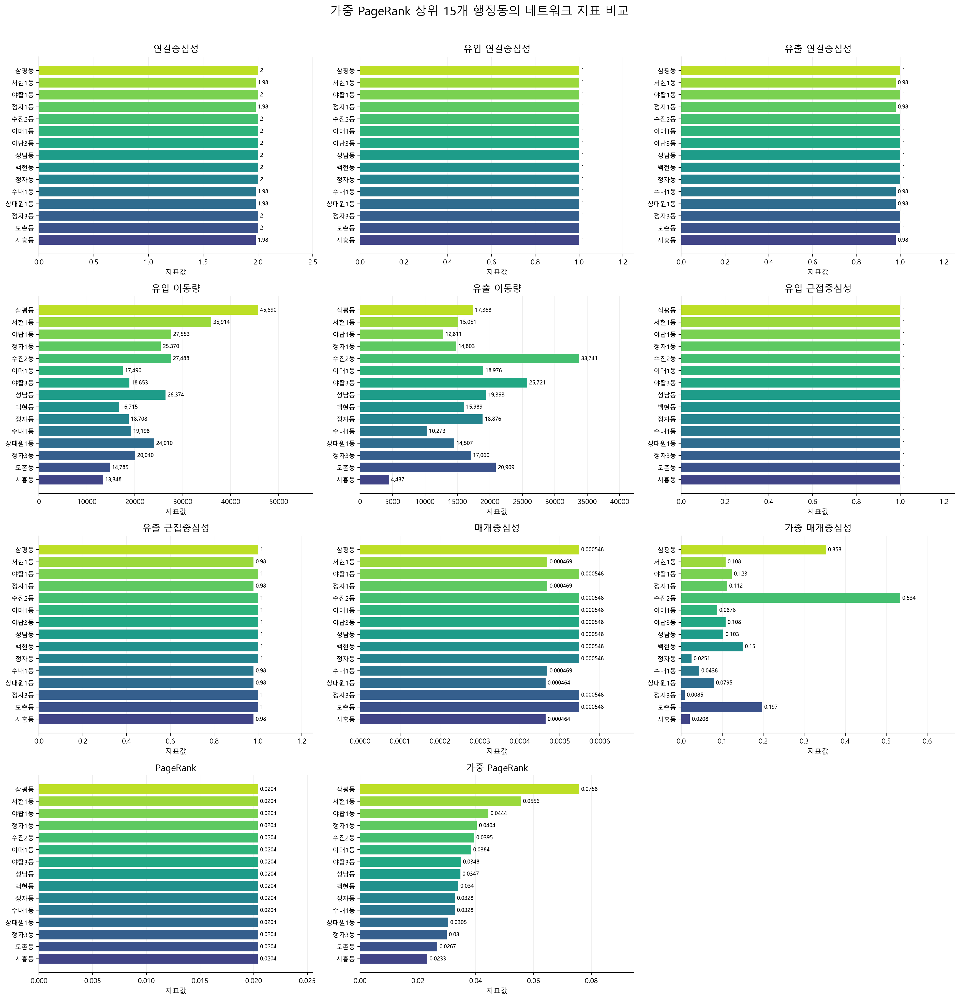

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# Windows 한글 폰트
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 가중 PageRank 상위 15개 행정동
top_n = 15
plot_df = (
    unique_dong
    .dropna(subset=["pagerank_w"])
    .drop_duplicates(subset="admdong_cd")
    .sort_values("pagerank_w", ascending=False)
    .head(top_n)
    .iloc[::-1]
)

titles = {
    "degree": "연결중심성",
    "in_degree": "유입 연결중심성",
    "out_degree": "유출 연결중심성",
    "in_strength": "유입 이동량",
    "out_strength": "유출 이동량",
    "closeness_in": "유입 근접중심성",
    "closeness_out": "유출 근접중심성",
    "betweenness": "매개중심성",
    "betweenness_w": "가중 매개중심성",
    "pagerank": "PageRank",
    "pagerank_w": "가중 PageRank",
}

metrics = [col for col in titles if col in plot_df.columns]

ncols = 3
nrows = (len(metrics) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(19, 5 * nrows),
    squeeze=False,
    facecolor="white",
)

# 모든 그래프에서 같은 행정동에 같은 색상 적용
colors = plt.colormaps["viridis"](np.linspace(0.2, 0.9, len(plot_df)))
y = np.arange(len(plot_df))

for ax, metric in zip(axes.flat, metrics):
    values = plot_df[metric].to_numpy()

    bars = ax.barh(y, values, color=colors)

    ax.set_yticks(y)
    ax.set_yticklabels(plot_df["emd_nm"], fontsize=9)
    ax.set_title(titles[metric], fontsize=13)
    ax.set_xlabel("지표값")

    # 실제 값 표시
    labels = [
        f"{v:,.0f}" if metric in ("in_strength", "out_strength")
        else f"{v:.3g}"
        for v in values
    ]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=8)

    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    ax.margins(x=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# 사용하지 않는 패널 숨기기
for ax in list(axes.flat)[len(metrics):]:
    ax.set_visible(False)

fig.suptitle(
    f"가중 PageRank 상위 {len(plot_df)}개 행정동의 네트워크 지표 비교",
    fontsize=17,
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### 지도위에 표현

In [30]:
print(bnd_dong_00_2022_2022_2Q_sungnam.shape)
bnd_dong_00_2022_2022_2Q_sungnam.head(5)

(50, 13)


,BASE_DATE,ADM_CD,ADM_NM,sgis_cd,sqkm,ha,lon,lat,sido_nm,emd_nm,sgg_nm,admdong_cd,geometry
625,20220630,31021510,신흥1동,31021510,0.323,32.260,127.141,37.441,경기도,신흥1동,성남시 수정구,41131510,"POLYGON ((127.14093 37.43766, 127.14092 37.437..."
626,20220630,31021520,신흥2동,31021520,1.140,114.028,127.148,37.450,경기도,신흥2동,성남시 수정구,41131520,"POLYGON ((127.15061 37.45703, 127.15051 37.456..."
627,20220630,31021530,신흥3동,31021530,0.321,32.116,127.147,37.443,경기도,신흥3동,성남시 수정구,41131530,"POLYGON ((127.145 37.43972, 127.14485 37.43964..."
628,20220630,31021540,태평1동,31021540,1.341,134.108,127.124,37.446,경기도,태평1동,성남시 수정구,41131540,"POLYGON ((127.12269 37.45485, 127.1226 37.4544..."
629,20220630,31021550,태평2동,31021550,0.482,48.225,127.136,37.448,경기도,태평2동,성남시 수정구,41131550,"POLYGON ((127.13749 37.45242, 127.13744 37.452..."


In [31]:
centrality_df

,degree,in_degree,out_degree,in_strength,out_strength,closeness_in,closeness_out,betweenness,betweenness_w,pagerank,pagerank_w
admdong_cd,,,,,,,,,,,
41131510,1.980,0.980,1.000,5957.449,5820.679,0.980,1.000,0.000,0.000,0.020,0.009
41131520,1.980,0.980,1.000,3754.403,7126.424,0.980,1.000,0.000,0.000,0.020,0.006
41131530,1.980,0.980,1.000,6919.638,9567.928,0.980,1.000,0.000,0.000,0.020,0.010
41131540,1.980,0.980,1.000,9846.768,10478.421,0.980,1.000,0.000,0.011,0.020,0.015
41131550,1.980,0.980,1.000,7212.504,9051.559,0.980,1.000,0.000,0.002,0.020,0.011
41131560,1.939,0.980,0.959,8351.052,8386.351,0.980,0.961,0.000,0.001,0.020,0.012
41131561,1.980,0.980,1.000,4078.400,7270.150,0.980,1.000,0.000,0.000,0.020,0.007
41131570,1.980,0.980,1.000,3527.150,6555.446,0.980,1.000,0.000,0.000,0.020,0.007
41131580,2.000,1.000,1.000,27487.918,33740.784,1.000,1.000,0.001,0.534,0.020,0.039


In [32]:
sungnam_centrality = pd.merge(bnd_dong_00_2022_2022_2Q_sungnam, centrality_df, on='admdong_cd', how='inner')
print(sungnam_centrality.count())
sungnam_centrality.head()

BASE_DATE        50
ADM_CD           50
ADM_NM           50
sgis_cd          50
sqkm             50
ha               50
lon              50
lat              50
sido_nm          50
emd_nm           50
sgg_nm           50
admdong_cd       50
geometry         50
degree           50
in_degree        50
out_degree       50
in_strength      50
out_strength     50
closeness_in     50
closeness_out    50
betweenness      50
betweenness_w    50
pagerank         50
pagerank_w       50
dtype: int64


,BASE_DATE,ADM_CD,ADM_NM,sgis_cd,sqkm,ha,lon,lat,sido_nm,emd_nm,...,in_degree,out_degree,in_strength,out_strength,closeness_in,closeness_out,betweenness,betweenness_w,pagerank,pagerank_w
0,20220630,31021510,신흥1동,31021510,0.323,32.260,127.141,37.441,경기도,신흥1동,...,0.980,1.000,5957.449,5820.679,0.980,1.000,0.000,0.000,0.020,0.009
1,20220630,31021520,신흥2동,31021520,1.140,114.028,127.148,37.450,경기도,신흥2동,...,0.980,1.000,3754.403,7126.424,0.980,1.000,0.000,0.000,0.020,0.006
2,20220630,31021530,신흥3동,31021530,0.321,32.116,127.147,37.443,경기도,신흥3동,...,0.980,1.000,6919.638,9567.928,0.980,1.000,0.000,0.000,0.020,0.010
3,20220630,31021540,태평1동,31021540,1.341,134.108,127.124,37.446,경기도,태평1동,...,0.980,1.000,9846.768,10478.421,0.980,1.000,0.000,0.011,0.020,0.015
4,20220630,31021550,태평2동,31021550,0.482,48.225,127.136,37.448,경기도,태평2동,...,0.980,1.000,7212.504,9051.559,0.980,1.000,0.000,0.002,0.020,0.011


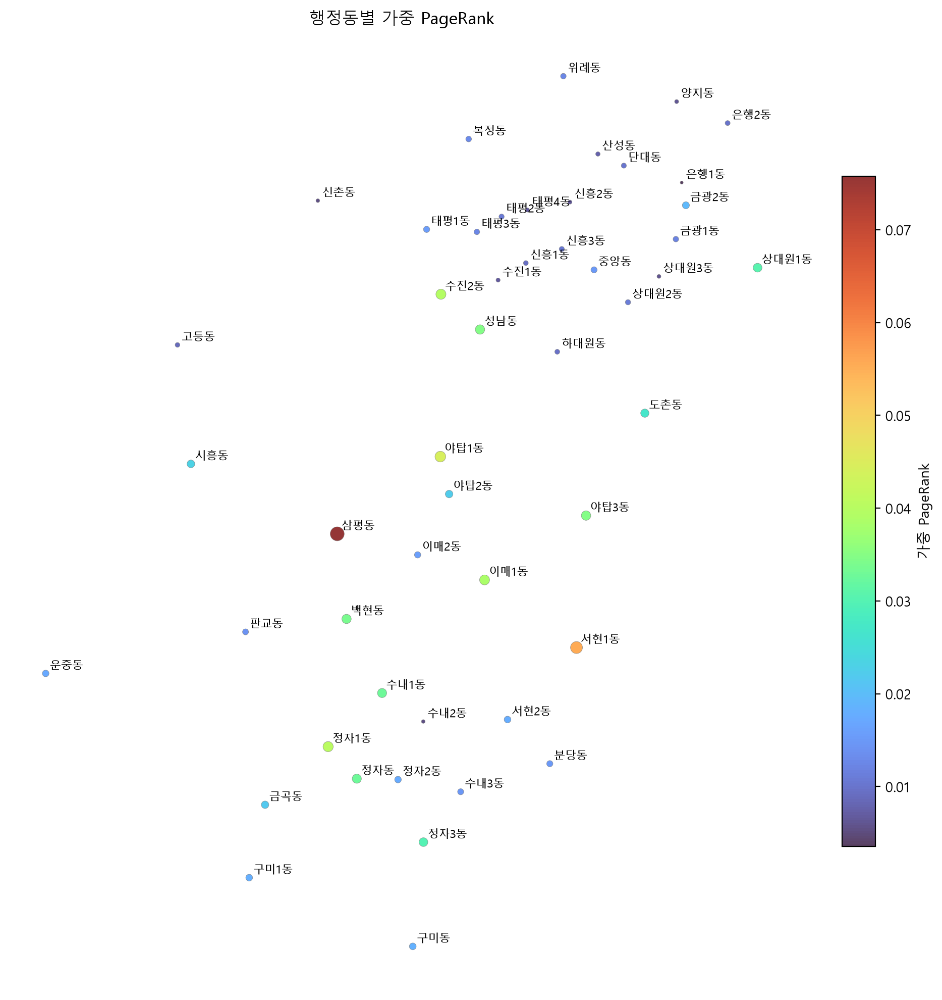

In [33]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

df = sungnam_centrality.dropna(
    subset=["lat", "lon", "pagerank_w"]
).copy()

# 점 크기: 최대 100 pt²
max_value = df["pagerank_w"].max()
sizes = (
    df["pagerank_w"] / max_value * 100
    if max_value > 0
    else [20] * len(df)
)

fig, ax = plt.subplots(figsize=(10, 10))

scatter = ax.scatter(
    df["lon"],
    df["lat"],
    c=df["pagerank_w"],
    s=sizes,
    cmap="turbo",
    alpha=0.8,
    edgecolors="grey",
    linewidths=0.3,
)

fig.colorbar(scatter, ax=ax, shrink=0.7, label="가중 PageRank")

ax.set_xlabel("경도")
ax.set_ylabel("위도")
ax.set_title("행정동별 가중 PageRank")
ax.grid(False)
ax.set_axis_off()

for _, row in df.iterrows():
    ax.annotate(
        row["emd_nm"],
        (row["lon"], row["lat"]),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=8,
    )
    
plt.tight_layout()
plt.show()

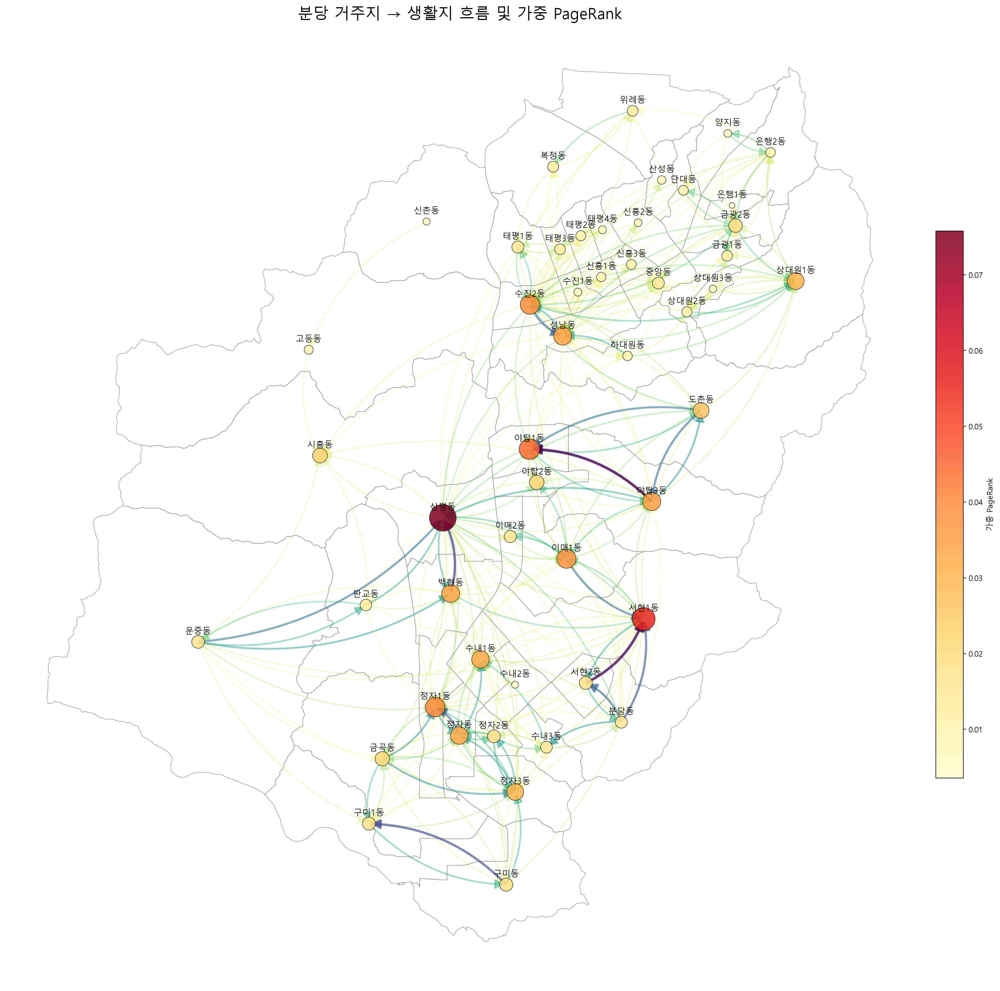

In [34]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import FancyArrowPatch

# 한글 폰트
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 전제: 흐름선의 출발·도착 좌표와 행정동 경계의 좌표계가 같아야 함
boundary = bnd_dong_00_2022_2022_2Q_sungnam.copy()

# ── 1. 흐름선 데이터 준비 ──
flow = (
    gdf.loc[gdf["tot"] > 0]
    .nlargest(300, "tot")
    .copy()
)

flow_cmap = mpl.colormaps["viridis_r"]
flow_norm = mcolors.Normalize(
    vmin=flow["tot"].min(),
    vmax=flow["tot"].max(),
)

# 이동량에 따른 투명도: 최소 이동량도 보이도록 0.15부터 설정
if flow["tot"].max() > flow["tot"].min():
    flow["alpha"] = 0.15 + 0.65 * flow_norm(flow["tot"].to_numpy())
else:
    flow["alpha"] = 0.6

# ── 2. 행정동 경계에 가중 PageRank 연결 ──
pr_values = centrality_df["pagerank_w"].copy()
pr_values.index = pr_values.index.astype("string").str.strip()

boundary["pagerank_w"] = (
    boundary["admdong_cd"]
    .astype("string")
    .str.strip()
    .map(pr_values)
)

# 중심점 계산: 위경도 좌표계이면 투영 후 계산하여 원래 좌표계로 복원
if boundary.crs is not None and boundary.crs.is_geographic:
    centers = (
        boundary.to_crs(epsg=5179)
        .geometry.centroid
        .to_crs(boundary.crs)
    )
else:
    centers = boundary.geometry.centroid

boundary["center_x"] = centers.x
boundary["center_y"] = centers.y

pr_map = boundary.dropna(
    subset=["pagerank_w", "center_x", "center_y"]
).copy()

# ── 3. 시각화 ──
fig, ax = plt.subplots(figsize=(20, 20))

# 행정동 경계
boundary.plot(
    ax=ax,
    facecolor="none",
    edgecolor="grey",
    linewidth=0.5,
    zorder=1,
)

# 흐름선: 거주지 → 생활지
# 이동량이 큰 흐름선을 나중에 그려 위에 표시
for _, row in flow.sort_values("tot").iterrows():
    start = row["geometry_rsdn"]
    end = row["geometry"]

    if start is None or end is None or start.is_empty or end.is_empty:
        continue

    arrow = FancyArrowPatch(
        (start.x, start.y),
        (end.x, end.y),
        connectionstyle="arc3,rad=0.2",
        arrowstyle="-|>",
        color=flow_cmap(flow_norm(row["tot"])),
        alpha=row["alpha"],
        linewidth=1 + 3 * row["alpha"],
        mutation_scale=25,
        zorder=2,
    )
    ax.add_patch(arrow)

# 가중 PageRank: 점의 색상과 면적으로 표현
if not pr_map.empty:
    max_pr = pr_map["pagerank_w"].max()
    sizes = (
        pr_map["pagerank_w"] / max_pr * 1200
        if max_pr > 0
        else [50] * len(pr_map)
    )

    pr_scatter = ax.scatter(
        pr_map["center_x"],
        pr_map["center_y"],
        s=sizes,
        c=pr_map["pagerank_w"],
        cmap="YlOrRd",
        alpha=0.85,
        edgecolors="black",
        linewidths=0.6,
        zorder=5,
    )

    fig.colorbar(
        pr_scatter,
        ax=ax,
        label="가중 PageRank",
        shrink=0.5,
        pad=0.02,
    )

# 행정동 이름
for _, row in boundary.dropna(subset=["center_x", "center_y"]).iterrows():
    ax.annotate(
        row["emd_nm"],
        (row["center_x"], row["center_y"]),
        xytext=(0, 8),
        textcoords="offset points",
        fontsize=11,
        color="black",
        ha="center",
        va="bottom",
        zorder=6,
    )

ax.set_title("분당 거주지 → 생활지 흐름 및 가중 PageRank", fontsize=20)
ax.set_axis_off()

plt.tight_layout()
plt.show()

# Louvain 커뮤니티 탐지

## 1. 개념

Louvain 알고리즘은 네트워크에서 서로 연결이 촘촘한 노드 집단, 즉 **커뮤니티(community)**를 찾는 방법이다. 노드와 엣지로 이루어진 그래프를 입력으로 받아, 같은 커뮤니티 안의 연결은 많고 다른 커뮤니티 사이의 연결은 적도록 노드를 묶는다.

알고리즘의 이름은 이 방법을 제안한 연구자들이 소속되어 있던 벨기에 루뱅대학교에서 유래했다. 그래프의 커뮤니티 구조를 **모듈성(modularity)**이라는 점수로 평가하며, 이 점수가 커지도록 반복적으로 노드를 재배치한다.

## 2. 모듈성

모듈성은 실제 네트워크의 커뮤니티 내부 연결이, 노드의 연결 정도를 고려한 무작위 네트워크에서 기대되는 내부 연결보다 얼마나 많은지를 나타낸다.

가중치가 없는 무방향 그래프에서 모듈성은 다음과 같이 쓸 수 있다.

$$
Q = \frac{1}{2m} \sum_{i,j}
\left(A_{ij} - \frac{k_i k_j}{2m}\right)
\delta(c_i,c_j)
$$

- $A_{ij}$: 노드 $i$와 $j$가 연결되어 있으면 1, 아니면 0
- $k_i, k_j$: 각 노드의 차수(연결 수)
- $m$: 그래프의 전체 엣지 수
- $c_i$: 노드 $i$가 속한 커뮤니티
- $\delta(c_i,c_j)$: 두 노드가 같은 커뮤니티면 1, 아니면 0

모듈성이 높을수록 커뮤니티 내부의 연결이 무작위 기준보다 상대적으로 많다는 뜻이다. 다만 모듈성은 커뮤니티 구조의 한 가지 기준일 뿐이며, 높은 점수가 항상 해당 분야에서 의미 있는 집단을 보장하지는 않는다.


## 3. 알고리즘의 작동 과정

Louvain은 크게 **노드 이동 단계**와 **네트워크 압축 단계**를 반복한다.

### 단계 A: 노드 이동

1. 처음에는 모든 노드를 각각 별도의 커뮤니티로 둔다.
2. 노드를 하나씩 살펴보고, 그 노드와 연결된 이웃 노드들의 커뮤니티로 옮겼을 때 모듈성이 증가하는지 계산한다.
3. 모듈성을 가장 크게 높이는 커뮤니티로 노드를 이동한다. 증가하는 이동이 없으면 현재 위치에 둔다.
4. 더 이상 모듈성이 개선되지 않을 때까지 노드들을 반복해서 살펴본다.

이 단계가 끝나면 개별 노드보다 큰 커뮤니티가 만들어진다.

### 단계 B: 네트워크 압축

1. 각 커뮤니티를 하나의 슈퍼노드(supernode)로 합친다.
2. 서로 다른 커뮤니티 사이의 엣지 가중치는 새 슈퍼노드 사이의 엣지로 합산한다.
3. 같은 커뮤니티 안의 엣지는 슈퍼노드의 내부 연결로 반영한다.
4. 압축된 그래프에서 다시 노드 이동 단계를 수행한다.

더 이상 모듈성이 개선되지 않을 때까지 두 단계를 반복한다. 압축 단계 덕분에 상위 수준의 커뮤니티 구조도 찾을 수 있다.

## 4. 간단한 직관

친구 관계 네트워크를 생각해 보자. 한 사람을 현재 집단에서 다른 집단으로 옮겼을 때, 옮긴 뒤 그 사람의 연결이 새 집단 안에 더 많이 모이고 집단 간 연결은 상대적으로 줄어든다면 모듈성이 높아질 수 있다. Louvain은 이런 이동을 반복하고, 형성된 집단들을 다시 큰 단위로 묶어 더 넓은 구조를 살핀다.

## 5. 의사 코드

```text
각 노드를 하나의 커뮤니티로 초기화

반복:
    각 노드를 차례로 확인:
        노드를 이웃 커뮤니티로 옮겼을 때의 모듈성 변화를 계산
        모듈성이 가장 개선되는 커뮤니티로 이동
    더 이상 개선되는 이동이 없으면 멈춤

    커뮤니티마다 하나의 슈퍼노드를 만들어 그래프를 압축
    압축된 그래프에서 노드 이동을 다시 수행

최종 커뮤니티 할당 반환
```

## 6. 장점과 한계

### 장점

- 네트워크를 압축하면서 탐색하므로 대규모 그래프에도 비교적 빠르게 적용할 수 있다.
- 가중치가 있는 네트워크에도 사용할 수 있다.
- 사전에 커뮤니티 개수를 지정하지 않아도 된다.
- 여러 수준의 커뮤니티 구조를 단계적으로 발견할 수 있다.

### 한계와 주의점

- 노드를 어떤 순서로 처리하는지, 초기 상태와 난수 시드가 무엇인지에 따라 결과가 달라질 수 있다.
- 모듈성 최대화에는 **해상도 한계(resolution limit)**가 있어, 작은 커뮤니티를 합쳐 큰 커뮤니티로 볼 수 있다.
- 모듈성이 비슷한 여러 분할이 존재할 수 있어, 한 번의 실행 결과만으로 구조를 단정하기 어렵다.
- 방향 그래프, 자기 루프, 엣지 가중치 처리 방식은 사용하는 라이브러리의 정의를 확인해야 한다.
- 커뮤니티는 그래프의 연결 패턴을 요약한 결과다. 커뮤니티 이름이나 사회적 의미는 분석 맥락에 맞춰 별도로 해석해야 한다.

## 7. 적용할 때 확인할 사항

1. **노드와 엣지의 정의**: 무엇을 개체로 보고 어떤 관계를 연결로 볼지 명확히 한다.
2. **엣지 가중치**: 연결 강도를 반영할지, 단순 연결 여부만 사용할지 정한다.
3. **그래프 방향성**: 관계가 방향성을 갖는지 확인하고 알고리즘 설정을 맞춘다.
4. **재현성**: 난수 시드와 라이브러리 버전을 기록한다.
5. **안정성**: 여러 번 실행하거나 해상도 설정을 바꿔 커뮤니티가 얼마나 일관적인지 비교한다.
6. **해석 검토**: 커뮤니티별 노드 특성과 실제 맥락을 함께 살펴본다.

## 8. 한 문장 요약

**Louvain은 모듈성이 증가하도록 노드를 이웃 커뮤니티로 이동시키고, 커뮤니티를 슈퍼노드로 압축해 같은 과정을 반복함으로써 네트워크의 계층적 집단 구조를 찾는 알고리즘이다.**

In [35]:
import networkx as nx
import pandas as pd

WEIGHT = "tot"

# 1. 방향 이동 그래프에서 가중 PageRank 계산
#    g의 edge attribute가 "tot"인지 확인하세요.
pagerank_w = nx.pagerank(
    g,
    alpha=0.9,
    weight=WEIGHT,
    max_iter=1000,
    tol=1e-10,
)

# 2. 커뮤니티 탐지용 무방향 그래프 생성
#    A→B와 B→A 이동량을 합쳐 두 동 사이의 총 이동량으로 사용
G_community = nx.Graph()
G_community.add_nodes_from(g.nodes())

for u, v, data in g.edges(data=True):
    flow = float(data.get(WEIGHT, 0))

    if u == v or flow <= 0:
        continue

    if G_community.has_edge(u, v):
        G_community[u][v]["flow"] += flow
    else:
        G_community.add_edge(u, v, flow=flow)

# 3. 이동량을 가중치로 Louvain 커뮤니티 탐지
communities = nx.community.louvain_communities(
    G_community,
    weight="flow",
    resolution=1.0,
    seed=42,
)

# 커뮤니티 번호를 재현 가능하게 부여
communities = sorted(communities, key=lambda c: min(map(str, c)))

community_id = {
    node: cid
    for cid, nodes in enumerate(communities)
    for node in nodes
}

# 4. 노드별 결과표
result = pd.DataFrame({
    "admdong_cd": list(G_community.nodes()),
    "community": [community_id[n] for n in G_community.nodes()],
    "pagerank_w": [pagerank_w.get(n, 0) for n in G_community.nodes()],
})

result["community_size"] = (
    result.groupby("community")["admdong_cd"].transform("size")
)

result["rank_in_community"] = (
    result.groupby("community")["pagerank_w"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

result = result.sort_values(
    ["community", "rank_in_community"]
).reset_index(drop=True)

# 5. 커뮤니티별 요약 및 모듈성
modularity = nx.community.modularity(
    G_community,
    communities,
    weight="flow",
)

community_summary = (
    result.groupby("community")
    .agg(
        dong_count=("admdong_cd", "size"),
        top_dong=("admdong_cd", "first"),
        top_dong_pagerank=("pagerank_w", "max"),
    )
    .sort_values("dong_count", ascending=False)
)

print(f"커뮤니티 수: {len(communities)}")
print(f"Modularity: {modularity:.4f}")
display(community_summary)
display(result)

커뮤니티 수: 3
Modularity: 0.3433


,dong_count,top_dong,top_dong_pagerank
community,,,
0,26,41131580,0.039
2,13,41135580,0.056
1,11,41135655,0.076


,admdong_cd,community,pagerank_w,community_size,rank_in_community
0,41131580,0,0.039,26,1
1,41133510,0,0.035,26,2
2,41133570,0,0.030,26,3
3,41133540,0,0.020,26,4
4,41131540,0,0.015,26,5
5,41133525,0,0.015,26,6
6,41131620,0,0.013,26,7
7,41131625,0,0.012,26,8
8,41131560,0,0.012,26,9
9,41133530,0,0.012,26,10


In [37]:
print(boundary.shape)
boundary.head()

(50, 16)


,BASE_DATE,ADM_CD,ADM_NM,sgis_cd,sqkm,ha,lon,lat,sido_nm,emd_nm,sgg_nm,admdong_cd,geometry,pagerank_w,center_x,center_y
625,20220630,31021510,신흥1동,31021510,0.323,32.260,127.141,37.441,경기도,신흥1동,성남시 수정구,41131510,"POLYGON ((127.14093 37.43766, 127.14092 37.437...",0.009,127.141,37.441
626,20220630,31021520,신흥2동,31021520,1.140,114.028,127.148,37.450,경기도,신흥2동,성남시 수정구,41131520,"POLYGON ((127.15061 37.45703, 127.15051 37.456...",0.006,127.148,37.450
627,20220630,31021530,신흥3동,31021530,0.321,32.116,127.147,37.443,경기도,신흥3동,성남시 수정구,41131530,"POLYGON ((127.145 37.43972, 127.14485 37.43964...",0.010,127.147,37.443
628,20220630,31021540,태평1동,31021540,1.341,134.108,127.124,37.446,경기도,태평1동,성남시 수정구,41131540,"POLYGON ((127.12269 37.45485, 127.1226 37.4544...",0.015,127.124,37.446
629,20220630,31021550,태평2동,31021550,0.482,48.225,127.136,37.448,경기도,태평2동,성남시 수정구,41131550,"POLYGON ((127.13749 37.45242, 127.13744 37.452...",0.011,127.136,37.448


In [38]:
boundary=boundary.merge(
    result,
    left_on="admdong_cd",
    right_on="admdong_cd",
    how="left",
    validate="many_to_one",
)   

print(boundary.count())
boundary.head()

BASE_DATE            50
ADM_CD               50
ADM_NM               50
sgis_cd              50
sqkm                 50
ha                   50
lon                  50
lat                  50
sido_nm              50
emd_nm               50
sgg_nm               50
admdong_cd           50
geometry             50
pagerank_w_x         50
center_x             50
center_y             50
community            50
pagerank_w_y         50
community_size       50
rank_in_community    50
dtype: int64


,BASE_DATE,ADM_CD,ADM_NM,sgis_cd,sqkm,ha,lon,lat,sido_nm,emd_nm,sgg_nm,admdong_cd,geometry,pagerank_w_x,center_x,center_y,community,pagerank_w_y,community_size,rank_in_community
0,20220630,31021510,신흥1동,31021510,0.323,32.260,127.141,37.441,경기도,신흥1동,성남시 수정구,41131510,"POLYGON ((127.14093 37.43766, 127.14092 37.437...",0.009,127.141,37.441,0,0.009,26,17
1,20220630,31021520,신흥2동,31021520,1.140,114.028,127.148,37.450,경기도,신흥2동,성남시 수정구,41131520,"POLYGON ((127.15061 37.45703, 127.15051 37.456...",0.006,127.148,37.450,0,0.006,26,22
2,20220630,31021530,신흥3동,31021530,0.321,32.116,127.147,37.443,경기도,신흥3동,성남시 수정구,41131530,"POLYGON ((127.145 37.43972, 127.14485 37.43964...",0.010,127.147,37.443,0,0.010,26,13
3,20220630,31021540,태평1동,31021540,1.341,134.108,127.124,37.446,경기도,태평1동,성남시 수정구,41131540,"POLYGON ((127.12269 37.45485, 127.1226 37.4544...",0.015,127.124,37.446,0,0.015,26,5
4,20220630,31021550,태평2동,31021550,0.482,48.225,127.136,37.448,경기도,태평2동,성남시 수정구,41131550,"POLYGON ((127.13749 37.45242, 127.13744 37.452...",0.011,127.136,37.448,0,0.011,26,12


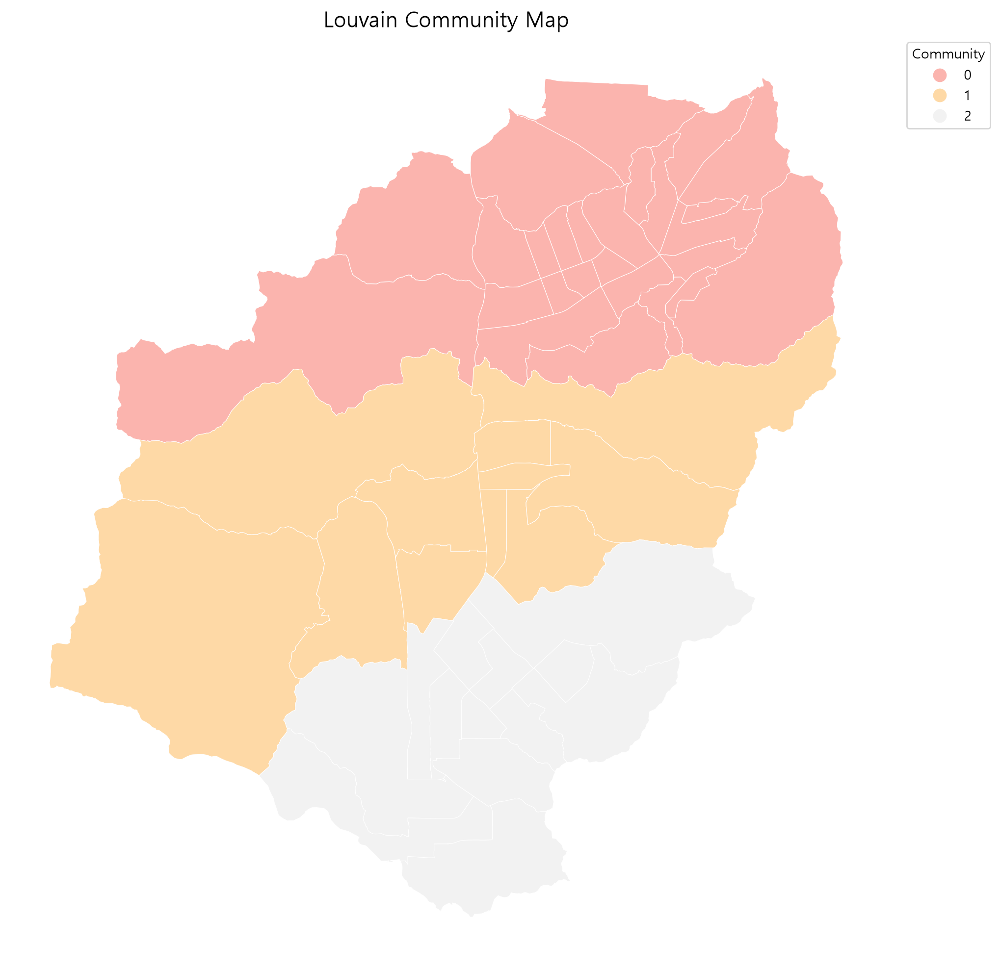

In [44]:
import matplotlib.pyplot as plt

# community 값이 없는 행은 별도 범주로 표시
plot_gdf = boundary.copy()
plot_gdf["community"] = (
    plot_gdf["community"]
    .astype("Int64")
    .astype("string")
    .fillna("미분류")
)

fig, ax = plt.subplots(figsize=(10, 10))

plot_gdf.plot(
    column="community",
    categorical=True,
    cmap="Pastel1",
    legend=True,
    linewidth=0.4,
    edgecolor="white",
    ax=ax,
    legend_kwds={
        "title": "Community",
        "loc": "upper left",
        "bbox_to_anchor": (1.02, 1),
    },
)

ax.set_title("Louvain Community Map", fontsize=16)
ax.set_axis_off()
plt.tight_layout()
plt.show()

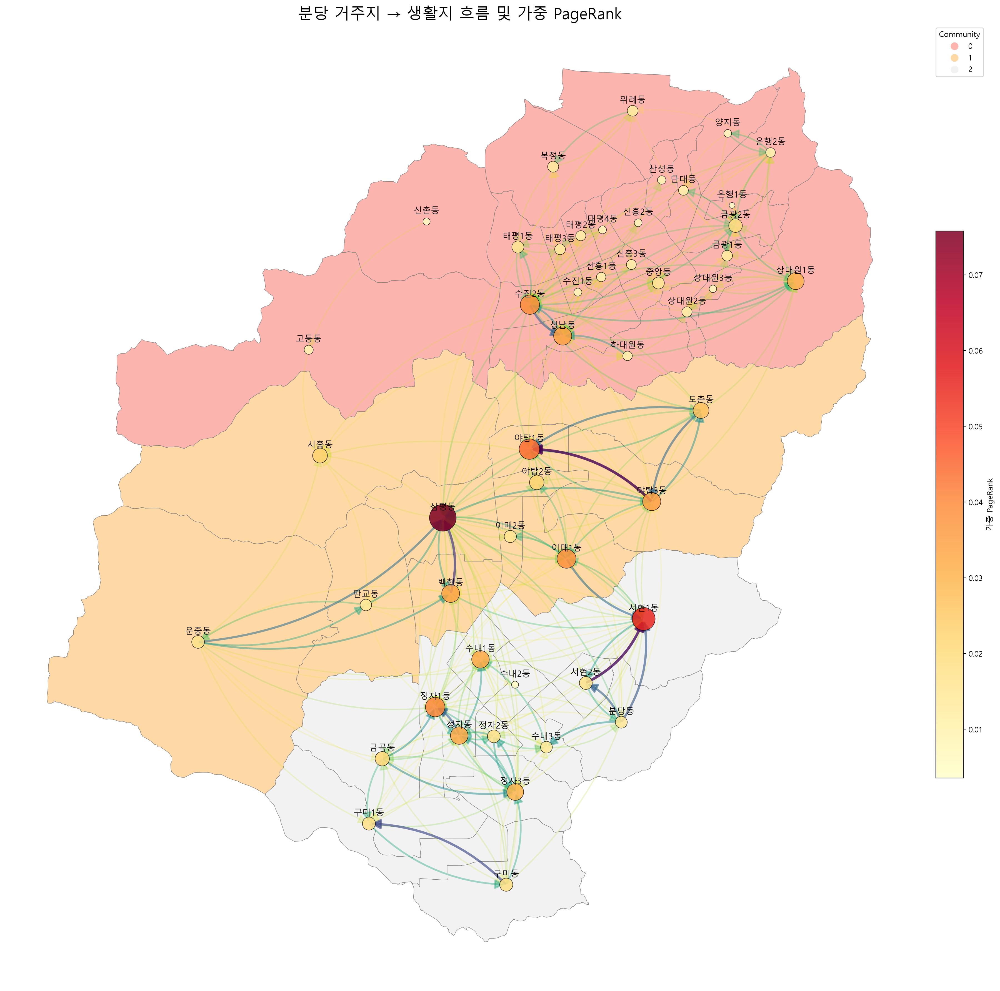

In [42]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import FancyArrowPatch

# 한글 폰트
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 전제: 흐름선의 출발·도착 좌표와 행정동 경계의 좌표계가 같아야 함
boundary = bnd_dong_00_2022_2022_2Q_sungnam.copy()

# 조인 키 형식을 맞춘 뒤 community를 연결
boundary["admdong_cd"] = (
    boundary["admdong_cd"].astype("string").str.strip()
)

community_result = result[["admdong_cd", "community"]].copy()
community_result["admdong_cd"] = (
    community_result["admdong_cd"].astype("string").str.strip()
)

boundary = boundary.merge(
    community_result.drop_duplicates("admdong_cd"),
    on="admdong_cd",
    how="left",
)

boundary["community"] = (
    boundary["community"]
    .astype("Int64")
    .astype("string")
    .fillna("미분류")
)


# ── 1. 흐름선 데이터 준비 ──
flow = (
    gdf.loc[gdf["tot"] > 0]
    .nlargest(300, "tot")
    .copy()
)

flow_cmap = mpl.colormaps["viridis_r"]
flow_norm = mcolors.Normalize(
    vmin=flow["tot"].min(),
    vmax=flow["tot"].max(),
)

# 이동량에 따른 투명도: 최소 이동량도 보이도록 0.15부터 설정
if flow["tot"].max() > flow["tot"].min():
    flow["alpha"] = 0.15 + 0.65 * flow_norm(flow["tot"].to_numpy())
else:
    flow["alpha"] = 0.6

# ── 2. 행정동 경계에 가중 PageRank 연결 ──
pr_values = centrality_df["pagerank_w"].copy()
pr_values.index = pr_values.index.astype("string").str.strip()

boundary["pagerank_w"] = (
    boundary["admdong_cd"]
    .astype("string")
    .str.strip()
    .map(pr_values)
)

# 중심점 계산: 위경도 좌표계이면 투영 후 계산하여 원래 좌표계로 복원
if boundary.crs is not None and boundary.crs.is_geographic:
    centers = (
        boundary.to_crs(epsg=5179)
        .geometry.centroid
        .to_crs(boundary.crs)
    )
else:
    centers = boundary.geometry.centroid

boundary["center_x"] = centers.x
boundary["center_y"] = centers.y

pr_map = boundary.dropna(
    subset=["pagerank_w", "center_x", "center_y"]
).copy()

# ── 3. 시각화 ──
fig, ax = plt.subplots(figsize=(20, 20))

# 행정동 경계: Louvain community별로 색상 구분
boundary.plot(
    ax=ax,
    column="community",
    categorical=True,
    cmap="Pastel1",
    legend=True,
    legend_kwds={
        "title": "Community",
        "loc": "upper left",
        "bbox_to_anchor": (1.02, 1),
    },
    edgecolor="grey",
    linewidth=0.5,
    zorder=1,
)

# 흐름선: 거주지 → 생활지
# 이동량이 큰 흐름선을 나중에 그려 위에 표시
for _, row in flow.sort_values("tot").iterrows():
    start = row["geometry_rsdn"]
    end = row["geometry"]

    if start is None or end is None or start.is_empty or end.is_empty:
        continue

    arrow = FancyArrowPatch(
        (start.x, start.y),
        (end.x, end.y),
        connectionstyle="arc3,rad=0.2",
        arrowstyle="-|>",
        color=flow_cmap(flow_norm(row["tot"])),
        alpha=row["alpha"],
        linewidth=1 + 3 * row["alpha"],
        mutation_scale=25,
        zorder=2,
    )
    ax.add_patch(arrow)

# 가중 PageRank: 점의 색상과 면적으로 표현
if not pr_map.empty:
    max_pr = pr_map["pagerank_w"].max()
    sizes = (
        pr_map["pagerank_w"] / max_pr * 1200
        if max_pr > 0
        else [50] * len(pr_map)
    )

    pr_scatter = ax.scatter(
        pr_map["center_x"],
        pr_map["center_y"],
        s=sizes,
        c=pr_map["pagerank_w"],
        cmap="YlOrRd",
        alpha=0.85,
        edgecolors="black",
        linewidths=0.6,
        zorder=5,
    )

    fig.colorbar(
        pr_scatter,
        ax=ax,
        label="가중 PageRank",
        shrink=0.5,
        pad=0.02,
    )

# 행정동 이름
for _, row in boundary.dropna(subset=["center_x", "center_y"]).iterrows():
    ax.annotate(
        row["emd_nm"],
        (row["center_x"], row["center_y"]),
        xytext=(0, 8),
        textcoords="offset points",
        fontsize=11,
        color="black",
        ha="center",
        va="bottom",
        zorder=6,
    )

ax.set_title("분당 거주지 → 생활지 흐름 및 가중 PageRank", fontsize=20)
ax.set_axis_off()

plt.tight_layout()
plt.show()